In [1]:
# --- project-root bootstrap: make this notebook CWD-independent (auto-added) ---
import os as _os
_root = _os.path.abspath(_os.getcwd())
while not _os.path.exists(_os.path.join(_root, 'data', 'raw', 'Train_Set.csv')) and _root != _os.path.dirname(_root):
    _root = _os.path.dirname(_root)
_os.chdir(_root)
# --- end bootstrap ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import classification_report
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import accuracy_score


train = pd.read_csv('data/raw/Train_Set.csv') #, delimiter=',', dtype=None, encoding=None )

train['class_label'] = train['class_label'].replace(['healthy', 'early stage cancer', 'screening stage cancer', 'mid stage cancer', 'late stage cancer'], [0, 1, 1, 1, 1])
train_x = train.iloc[:,:-1]
train_y = train.iloc[:,-1]

test = pd.read_csv('data/raw/Test_Set.csv') #, delimiter = ',', dtype = None, encoding = None)
test['class_label'] = test['class_label'].replace(['healthy', 'early stage cancer', 'screening stage cancer', 'mid stage cancer', 'late stage cancer'], [0, 1, 1, 1, 1])
test_x = test.iloc[:,:-1]
test_y = test.iloc[:,-1]


undersample = RandomUnderSampler(sampling_strategy = 1)

train_x , train_y = undersample.fit_resample(train_x, train_y)
# NOTE: never resample the test set - it must keep the real class distribution

def train_knn_classifier(train_x, train_y, n_neighbors=3):
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(train_x, train_y)
    return knn

def evaluate_classifier(clf, test_x, test_y):
    predictions = clf.predict(test_x)
    accuracy = accuracy_score(test_y, predictions)
    return accuracy

def cross_validate_classifier(clf, train_x, train_y, cv=5):
    cv_scores = cross_val_score(clf, train_x, train_y, cv=cv)
    return cv_scores

In [2]:
knn2 = KNeighborsClassifier()

param_grid = {'n_neighbors': np.arange(1,25)}

knn_gscv = GridSearchCV(knn2, param_grid, cv = 5)

knn_gscv.fit(train_x,train_y)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24])})

In [3]:
knn_gscv.best_params_

{'n_neighbors': 4}

In [4]:
knn_gscv.best_score_

0.6166666666666667

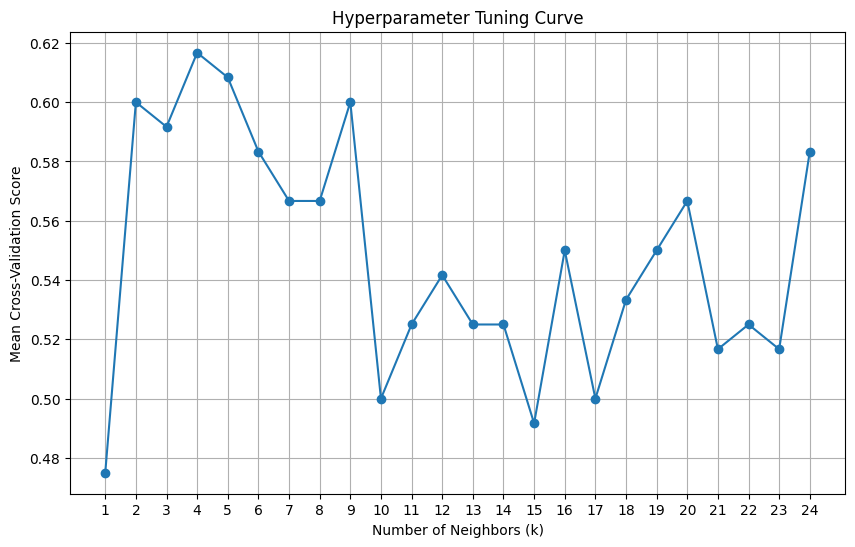

In [5]:
means = knn_gscv.cv_results_['mean_test_score']
params = knn_gscv.cv_results_['param_n_neighbors'].data.astype(int)

plt.figure(figsize=(10, 6))
plt.plot(params, means, marker='o', linestyle='-')
plt.title('Hyperparameter Tuning Curve')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Cross-Validation Score')
plt.xticks(np.arange(1, 25, step=1))  # Adjust the range of x-axis ticks as needed
plt.grid(True)
plt.show()

In [6]:
best_k = knn_gscv.best_params_['n_neighbors'] # k chosen by cross-validation
knn = train_knn_classifier(train_x, train_y, n_neighbors=best_k)
accuracy = evaluate_classifier(knn, test_x, test_y)
print("Best k:", best_k)
print("Accuracy on test data:", accuracy)

Best k: 4
Accuracy on test data: 0.4816247582205029


In [7]:
cv_scores = cross_validate_classifier(knn, train_x, train_y)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())

Cross-validation scores: [0.70833333 0.58333333 0.54166667 0.45833333 0.79166667]
Mean CV score: 0.6166666666666667
